In [ ]:
# FlowCast: AI-Powered Smart Traffic Flow Prediction Platform

## Project Overview

FlowCast is an AI-driven traffic analytics platform designed to predict traffic volume using machine learning.

The project analyses traffic conditions such as average vehicle speed, road occupancy, and road capacity to estimate traffic volume.

## Objectives
- Analyse traffic data.
- Clean and prepare the dataset.
- Train a machine learning model.
- Predict traffic volume.
- Display predictions through a Streamlit dashboard.


In [1]:
print("FlowCast notebook is working!")


FlowCast notebook is working!


In [2]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
import os

print("Project folders:")
print(os.listdir(".."))


Project folders:
['dashboard', 'data', 'data_and_documents', 'e66b00359860d20d922be58a65e87993 (1).zip', 'e66b00359860d20d922be58a65e87993.zip', 'main.py', 'models', 'notebooks', 'reports', 'requirements.txt', 'src', 'venv']


FLOWCAST PROJECT
Project folder: d:\Flowcast

TRAFFIC DATASET LOADED
Shape: (178468, 17)


,road_id,road_name,latitude,longitude,weather_station_id,date,time,traffic_volume,vehicle_count,vehicle_type_dist,avg_speed,occupancy,congestion_level,travel_time,accident_count,signal_timing,road_capacity
0,NL-007,Kingsway @ Park,28.647903,77.149142,WS-NORTH,2025-02-26,07:30,706.0,706,"{""2W"": 0.37, ""Car"": 0.43, ""LCV"": 0.11, ""HCV"": ...",31.2,59.6,Moderate,2.12,0,54,1928
1,NL-014,Industrial Link B,28.594749,77.253501,WS-CENTRAL,2025-03-23,21:00,308.0,308,"{""2W"": 0.43, ""Car"": 0.39, ""LCV"": 0.08, ""HCV"": ...",53.5,16.8,Free-flow,2.03,0,32,2327
2,NL-022,Old Town @ Clock,28.674521,77.219835,WS-NORTH,2025-04-05,11:00,342.0,342,"{""2W"": 0.4, ""Car"": 0.33, ""LCV"": 0.15, ""HCV"": 0...",49.9,27.5,Free-flow,3.46,0,38,1771
3,NL-006,Central Flyover E,28.622342,77.258257,WS-SOUTH,2025-05-04,01:30,187.0,187,"{""2W"": 0.41, ""Car"": 0.39, ""LCV"": 0.11, ""HCV"": ...",55.1,10.7,Free-flow,2.18,0,30,2285
4,NL-014,Industrial Link B,28.594749,77.253501,WS-CENTRAL,2025-01-08,12:30,490.0,490,"{""2W"": 0.39, ""Car"": 0.4, ""LCV"": 0.1, ""HCV"": 0.11}",45.9,27.7,Free-flow,2.37,0,45,2327



WEATHER DATASET: weather_observations.csv
Shape: (10872, 7)

CALENDAR DATASET: calendar_events.csv
Shape: (151, 6)

TRAFFIC DATA INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 178468 entries, 0 to 178467
Data columns (total 17 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   road_id             178468 non-null  str    
 1   road_name           178468 non-null  str    
 2   latitude            178468 non-null  float64
 3   longitude           178468 non-null  float64
 4   weather_station_id  178468 non-null  str    
 5   date                178468 non-null  str    
 6   time                178468 non-null  str    
 7   traffic_volume      174081 non-null  float64
 8   vehicle_count       178468 non-null  int64  
 9   vehicle_type_dist   178468 non-null  str    
 10  avg_speed           174086 non-null  float64
 11  occupancy           174085 non-null  float64
 12  congestion_level    151585 non-null  str    
 13  tra

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
road_id,178468,25,NL-004,7169,NaN,NaN,NaN,NaN,NaN,NaN,NaN
road_name,178468,25,Harbour Rd @ Mill,7169,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,178468.0,NaN,NaN,NaN,28.628364,0.033813,28.564352,28.598693,28.626508,28.64983,28.682634
longitude,178468.0,NaN,NaN,NaN,77.198542,0.050544,77.106648,77.161851,77.196308,77.238916,77.312287
weather_station_id,178468,3,WS-NORTH,64263,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,178468,151,2025-05-24,1197,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time,178468,48,03:00,3747,NaN,NaN,NaN,NaN,NaN,NaN,NaN
traffic_volume,174081.0,NaN,NaN,NaN,430.61897,283.745371,-59.0,195.0,361.0,600.0,2090.0
vehicle_count,178468.0,NaN,NaN,NaN,431.41761,283.579215,41.0,195.0,362.0,601.0,2090.0
vehicle_type_dist,178468,8578,"{""2W"": 0.4, ""Car"": 0.38, ""LCV"": 0.12, ""HCV"": 0.1}",415,NaN,NaN,NaN,NaN,NaN,NaN,NaN



MISSING VALUES


,Missing Values
road_id,0
road_name,0
latitude,0
longitude,0
weather_station_id,0
date,0
time,0
traffic_volume,4387
vehicle_count,0
vehicle_type_dist,0


... (2 outputs left out)


FEATURE ENGINEERING COMPLETED


C:\Users\KITS\AppData\Local\Temp\ipykernel_17284\1298915430.py:171: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  traffic["day_of_week"] = traffic["date"].dt.dayofweek


,road_id,road_name,latitude,longitude,weather_station_id,date,time,traffic_volume,vehicle_count,vehicle_type_dist,...,congestion_level,travel_time,accident_count,signal_timing,road_capacity,year,month,day,day_of_week,hour
0,NL-007,Kingsway @ Park,28.647903,77.149142,WS-NORTH,2025-02-26,07:30,706.0,706,"{""2W"": 0.37, ""Car"": 0.43, ""LCV"": 0.11, ""HCV"": ...",...,Moderate,2.12,0,54,1928,2025,2,26,2,7
1,NL-014,Industrial Link B,28.594749,77.253501,WS-CENTRAL,2025-03-23,21:00,308.0,308,"{""2W"": 0.43, ""Car"": 0.39, ""LCV"": 0.08, ""HCV"": ...",...,Free-flow,2.03,0,32,2327,2025,3,23,6,21
2,NL-022,Old Town @ Clock,28.674521,77.219835,WS-NORTH,2025-04-05,11:00,342.0,342,"{""2W"": 0.4, ""Car"": 0.33, ""LCV"": 0.15, ""HCV"": 0...",...,Free-flow,3.46,0,38,1771,2025,4,5,5,11
3,NL-006,Central Flyover E,28.622342,77.258257,WS-SOUTH,2025-05-04,01:30,187.0,187,"{""2W"": 0.41, ""Car"": 0.39, ""LCV"": 0.11, ""HCV"": ...",...,Free-flow,2.18,0,30,2285,2025,5,4,6,1
4,NL-014,Industrial Link B,28.594749,77.253501,WS-CENTRAL,2025-01-08,12:30,490.0,490,"{""2W"": 0.39, ""Car"": 0.4, ""LCV"": 0.1, ""HCV"": 0.11}",...,Free-flow,2.37,0,45,2327,2025,1,8,2,12



TRAFFIC VOLUME STATISTICS
count    172353.000000
mean        430.647816
std         283.735126
min         -59.000000
25%         195.000000
50%         361.000000
75%         600.000000
max        2090.000000
Name: traffic_volume, dtype: float64


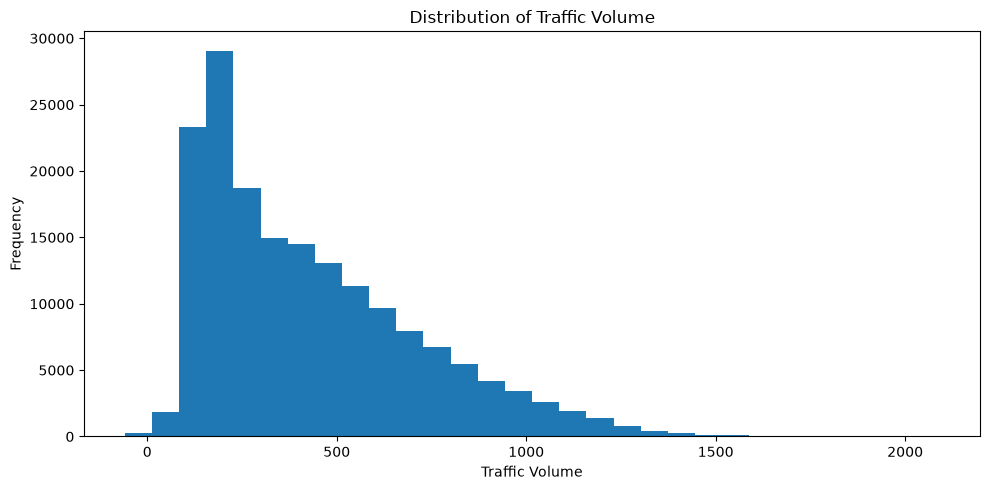


TOP 10 ROADS BY AVERAGE TRAFFIC


,Average Traffic Volume
road_name,
Central Flyover E,563.853988
Lakeview Connector,562.394844
Harbour Rd @ Mill,537.643889
Northline Ave @ 9th,536.096685
Central Flyover W,510.008141
Tech Park Spur,503.018551
Airport Underpass,491.607112
Industrial Link B,488.199187
Airport Feeder,483.716984


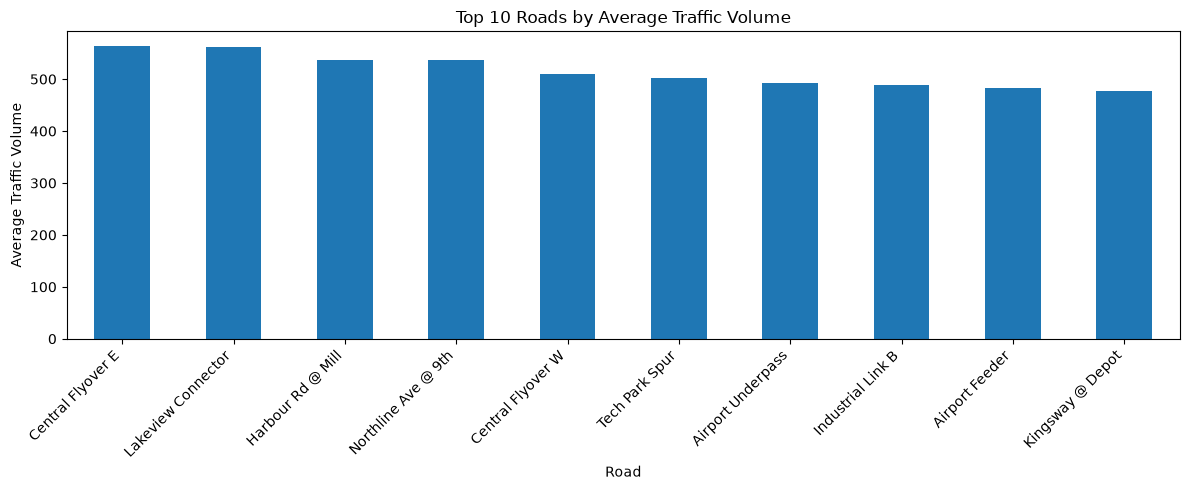

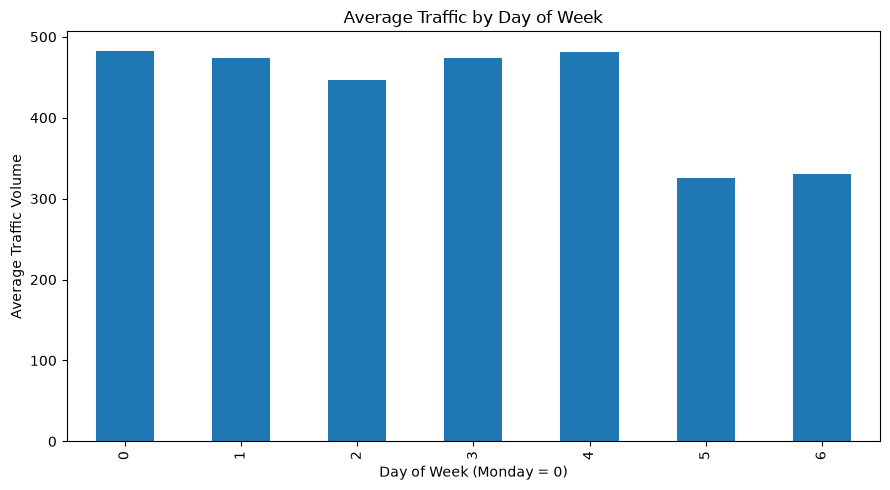

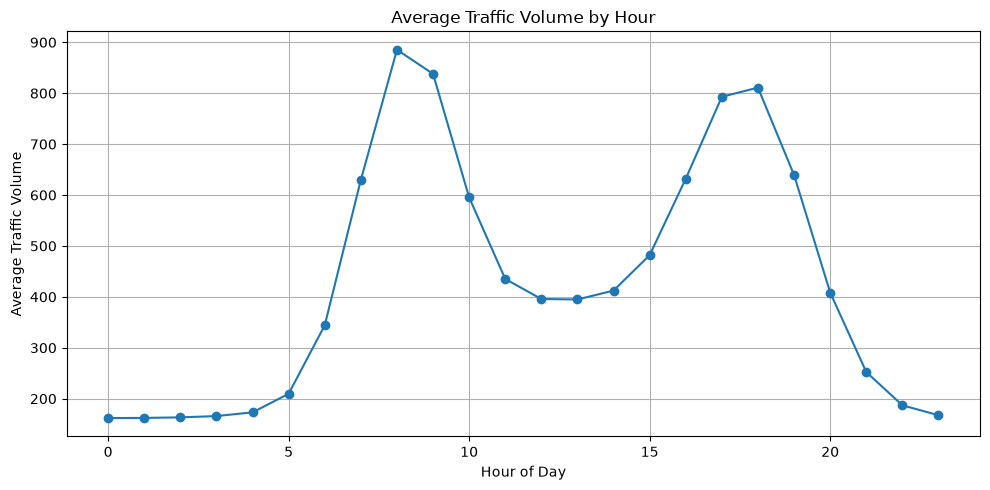


CONGESTION LEVEL COUNTS


,Count
congestion_level,
Free-flow,92107
Moderate,35818
Heavy,13873
Severe,8279


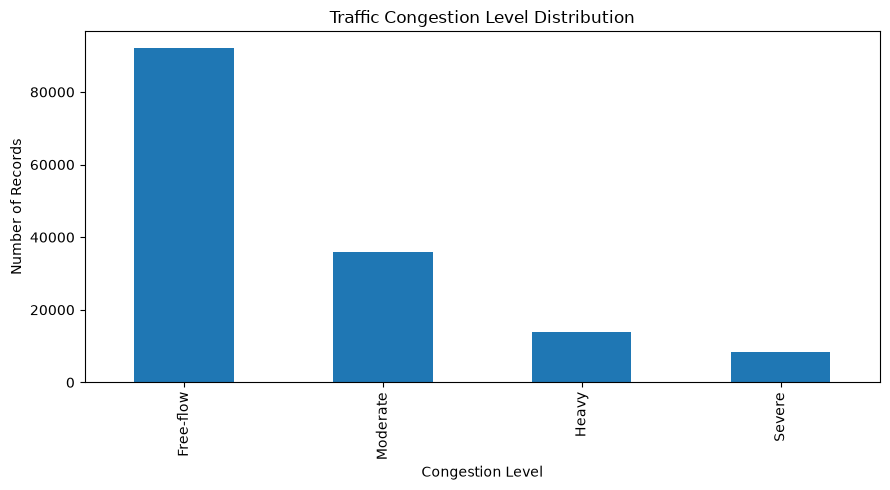


TRAVEL TIME SUMMARY


count    176701.000000
mean          3.565617
std           2.528680
min           0.800000
25%           2.200000
50%           3.120000
75%           4.090000
max          29.910000
Name: travel_time, dtype: float64

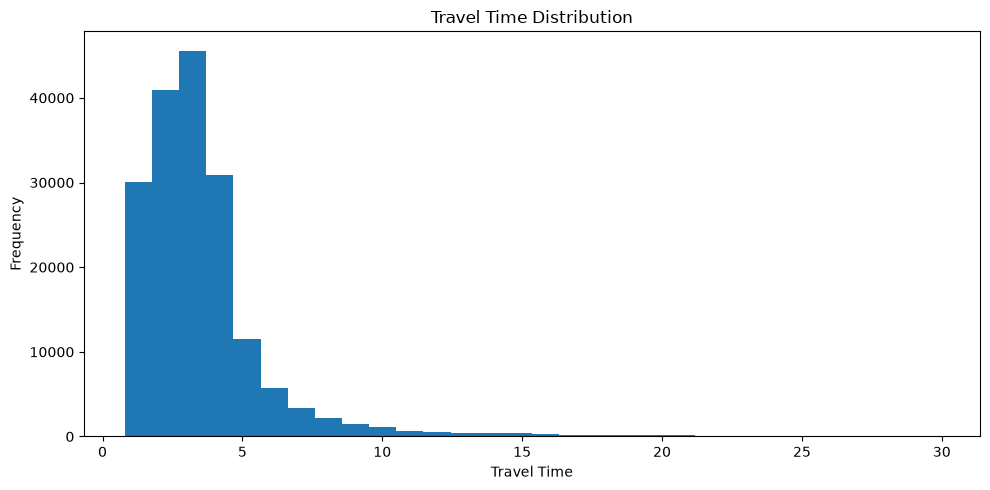


ACCIDENT COUNT SUMMARY


count    176701.000000
mean          0.009434
std           0.097544
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           2.000000
Name: accident_count, dtype: float64

Records with reported accidents: 1652


,Accident Count
road_name,
Central Flyover E,86
Airport Underpass,81
Grand Trunk @ Toll,80
Ring Road Terminus,80
Kingsway @ Depot,76
Tech Park @ Gate 3,76
Airport Feeder,75
Grand Trunk @ Ring,73
Industrial Link A,71



WEATHER MERGE COMPLETED
Combined dataset shape: (176701, 27)


,road_id,road_name,latitude,longitude,weather_station_id,date,time,traffic_volume,vehicle_count,vehicle_type_dist,...,year,month,day,day_of_week,hour,station_id,weather_condition,temperature,rainfall,visibility
0,NL-007,Kingsway @ Park,28.647903,77.149142,WS-NORTH,2025-02-26,07:30,706.0,706,"{""2W"": 0.37, ""Car"": 0.43, ""LCV"": 0.11, ""HCV"": ...",...,2025,2,26,2,7,NaN,NaN,NaN,NaN,NaN
1,NL-014,Industrial Link B,28.594749,77.253501,WS-CENTRAL,2025-03-23,21:00,308.0,308,"{""2W"": 0.43, ""Car"": 0.39, ""LCV"": 0.08, ""HCV"": ...",...,2025,3,23,6,21,NaN,NaN,NaN,NaN,NaN
2,NL-022,Old Town @ Clock,28.674521,77.219835,WS-NORTH,2025-04-05,11:00,342.0,342,"{""2W"": 0.4, ""Car"": 0.33, ""LCV"": 0.15, ""HCV"": 0...",...,2025,4,5,5,11,WS-NORTH,Clear,21.2,0.0,10000.0
3,NL-006,Central Flyover E,28.622342,77.258257,WS-SOUTH,2025-05-04,01:30,187.0,187,"{""2W"": 0.41, ""Car"": 0.39, ""LCV"": 0.11, ""HCV"": ...",...,2025,5,4,6,1,NaN,NaN,NaN,NaN,NaN
4,NL-014,Industrial Link B,28.594749,77.253501,WS-CENTRAL,2025-01-08,12:30,490.0,490,"{""2W"": 0.39, ""Car"": 0.4, ""LCV"": 0.1, ""HCV"": 0.11}",...,2025,1,8,2,12,NaN,NaN,NaN,NaN,NaN



WEATHER CONDITION COUNTS


,Count
weather_condition,
Clear,5647
Cloudy,1504
clear,1284
CLEAR,1237
Overcast,358
cloudy,340
Rain,307
Fog,59
rain,48


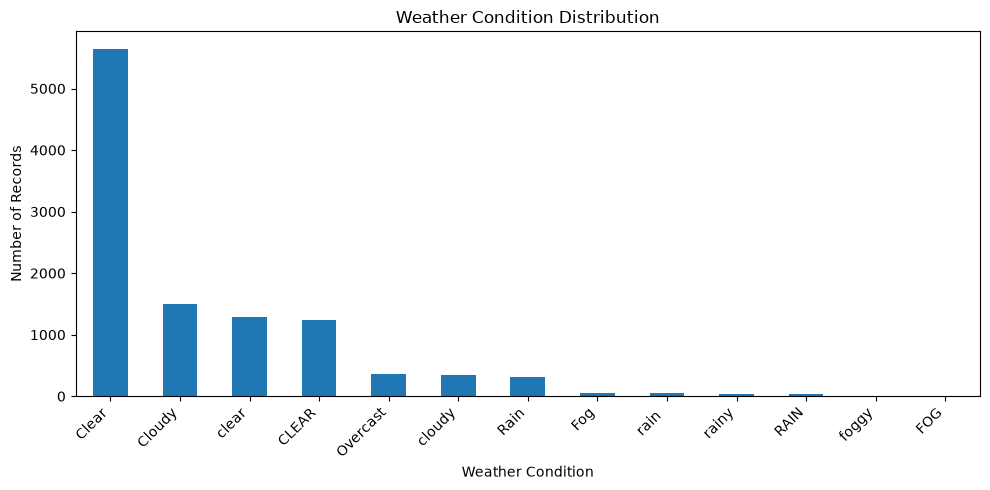


TRAFFIC FEATURE CORRELATION


,traffic_volume,vehicle_count,avg_speed,occupancy,travel_time,accident_count,road_capacity
traffic_volume,1.000000,0.997542,-0.723428,0.897726,0.534806,0.034384,0.264327
vehicle_count,0.997542,1.000000,-0.719987,0.898470,0.536361,0.035048,0.265616
avg_speed,-0.723428,-0.719987,1.000000,-0.724821,-0.540262,-0.032114,0.003286
occupancy,0.897726,0.898470,-0.724821,1.000000,0.594689,0.033913,-0.003420
travel_time,0.534806,0.536361,-0.540262,0.594689,1.000000,0.036458,-0.176491
accident_count,0.034384,0.035048,-0.032114,0.033913,0.036458,1.000000,-0.000290
road_capacity,0.264327,0.265616,0.003286,-0.003420,-0.176491,-0.000290,1.000000


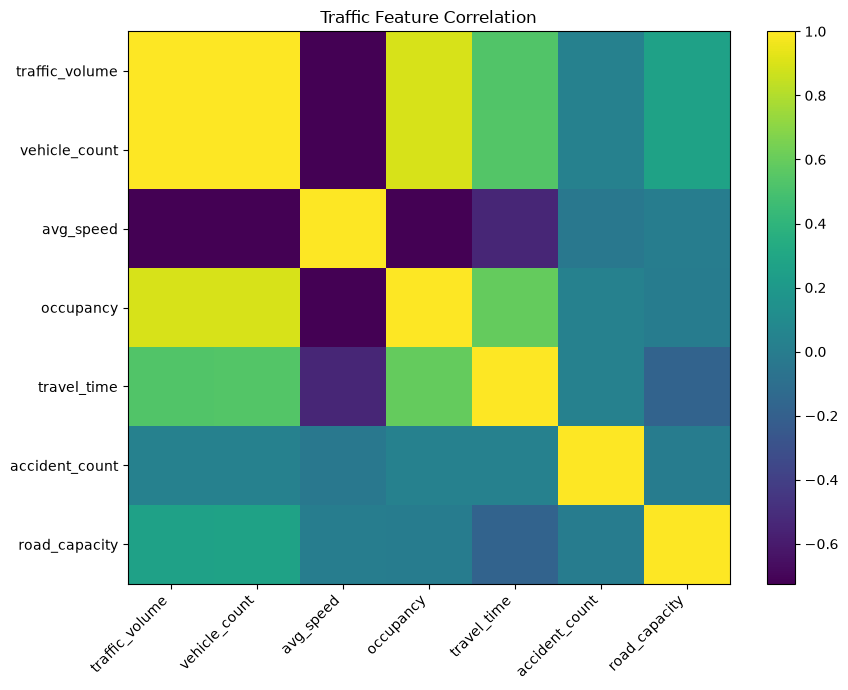


MACHINE LEARNING DATA
Rows available: 172114


,avg_speed,occupancy,road_capacity,traffic_volume
0,31.2,59.6,1928,706.0
1,53.5,16.8,2327,308.0
2,49.9,27.5,1771,342.0
3,55.1,10.7,2285,187.0
4,45.9,27.7,2327,490.0



TRAINING RECORDS: 137691
TESTING RECORDS: 34423

RANDOM FOREST MODEL TRAINING COMPLETED


,Actual Traffic Volume,Predicted Traffic Volume,Prediction Error
0,141.0,132.270000,8.730000
1,614.0,619.540000,-5.540000
2,409.0,392.218000,16.782000
3,634.0,657.180000,-23.180000
4,153.0,142.780000,10.220000
5,522.0,537.326333,-15.326333
6,679.0,702.000000,-23.000000
7,221.0,230.750000,-9.750000
8,730.0,775.800000,-45.800000
9,122.0,127.039000,-5.039000



MODEL PERFORMANCE
------------------------------
Mean Absolute Error: 20.82
Root Mean Squared Error: 29.64
R2 Score: 0.989


,Metric,Value
0,Mean Absolute Error,20.820431
1,Root Mean Squared Error,29.642183
2,R2 Score,0.988997


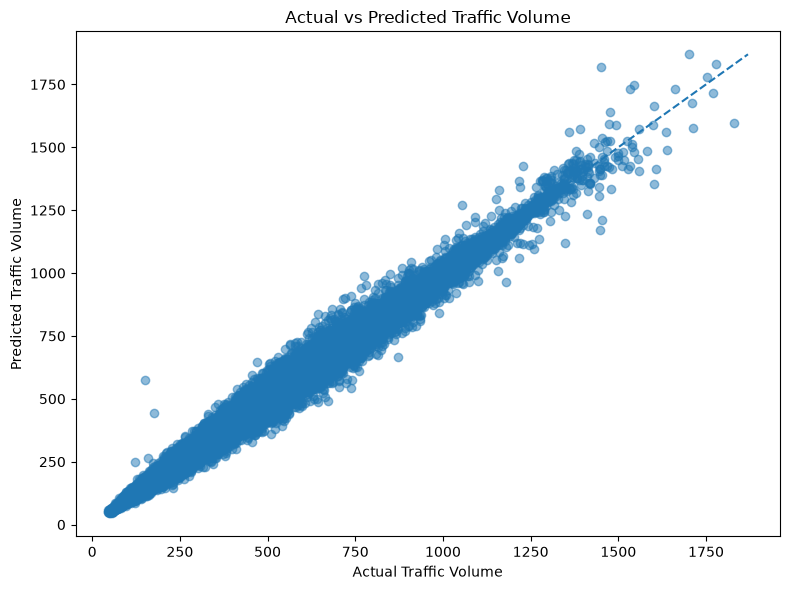

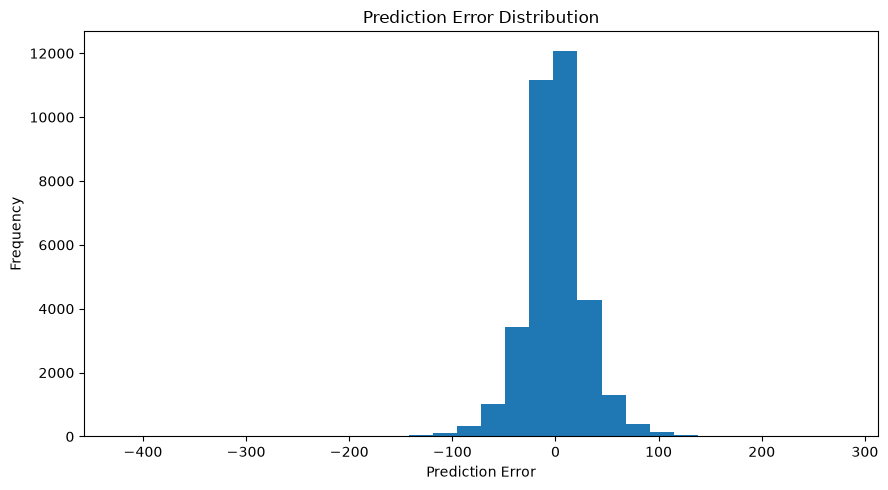

Average absolute prediction error: 20.82

FEATURE IMPORTANCE


,Feature,Importance
1,occupancy,0.756274
0,avg_speed,0.144793
2,road_capacity,0.098933


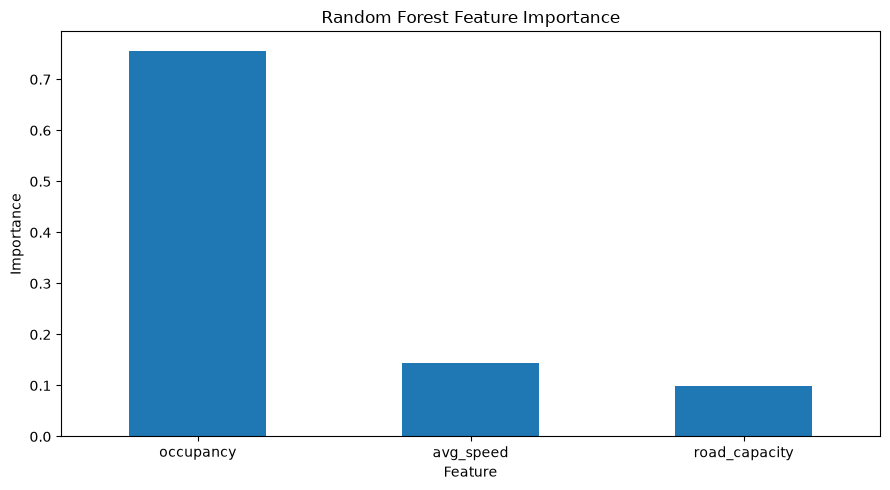


MODEL SAVED SUCCESSFULLY
d:\Flowcast\models\traffic_model.pkl

FILES SAVED
d:\Flowcast\reports\traffic_prediction_results.csv
d:\Flowcast\reports\model_evaluation_metrics.csv
d:\Flowcast\reports\feature_importance.csv
d:\Flowcast\reports\cleaned_traffic_data.csv

       FLOWCAST PROJECT SUMMARY
Traffic dataset records: 176701
ML records used: 172114
Training records: 137691
Testing records: 34423
Algorithm: Random Forest Regressor
Target: Traffic Volume
Features: ['avg_speed', 'occupancy', 'road_capacity']
MAE: 20.82
RMSE: 29.64
R2 Score: 0.989

Project analysis and model training completed.


In [4]:
# FLOWCAST - COMPLETE DATA ANALYSIS AND MACHINE LEARNING NOTEBOOK

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import os
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. PROJECT PATHS
# --------------------------------------------------

CURRENT_DIR = Path.cwd()
PROJECT_DIR = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR

DATA_DIR = PROJECT_DIR / "data_and_documents"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"

MODEL_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)

print("FLOWCAST PROJECT")
print("Project folder:", PROJECT_DIR)

# --------------------------------------------------
# 2. LOAD TRAFFIC DATASET
# --------------------------------------------------

traffic_path = DATA_DIR / "traffic_sensor_log.csv"

if not traffic_path.exists():
    matches = list(PROJECT_DIR.rglob("traffic_sensor_log.csv"))
    if matches:
        traffic_path = matches[0]
    else:
        raise FileNotFoundError(
            "traffic_sensor_log.csv was not found. "
            "Check the data_and_documents folder."
        )

traffic = pd.read_csv(traffic_path)

print("\nTRAFFIC DATASET LOADED")
print("Shape:", traffic.shape)
display(traffic.head())

# --------------------------------------------------
# 3. LOAD WEATHER DATASET IF AVAILABLE
# --------------------------------------------------

weather = None
weather_files = list(PROJECT_DIR.rglob("*.csv"))

for file in weather_files:
    if file == traffic_path:
        continue

    try:
        temp = pd.read_csv(file, nrows=5)
        columns = [str(c).lower() for c in temp.columns]

        if "station_id" in columns and "weather_condition" in columns:
            weather = pd.read_csv(file)
            print("\nWEATHER DATASET:", file.name)
            print("Shape:", weather.shape)
            break
    except Exception:
        pass

if weather is None:
    print("\nWeather dataset not detected. Continuing with traffic data.")

# --------------------------------------------------
# 4. LOAD CALENDAR DATASET IF AVAILABLE
# --------------------------------------------------

calendar = None

for file in weather_files:
    if file == traffic_path:
        continue

    try:
        temp = pd.read_csv(file, nrows=5)
        columns = [str(c).lower() for c in temp.columns]

        if "date" in columns and any(
            "holiday" in c or "event" in c for c in columns
        ):
            calendar = pd.read_csv(file)
            print("\nCALENDAR DATASET:", file.name)
            print("Shape:", calendar.shape)
            break
    except Exception:
        pass

if calendar is None:
    print("\nCalendar dataset not detected. Continuing without it.")

# --------------------------------------------------
# 5. DATASET INFORMATION
# --------------------------------------------------

print("\nTRAFFIC DATA INFORMATION")
traffic.info()

print("\nSTATISTICAL SUMMARY")
display(traffic.describe(include="all").T)

print("\nMISSING VALUES")
display(traffic.isnull().sum().to_frame("Missing Values"))

print("\nDUPLICATE ROWS")
print(traffic.duplicated().sum())

# --------------------------------------------------
# 6. DATA CLEANING
# --------------------------------------------------

traffic.columns = traffic.columns.str.strip()

traffic = traffic.drop_duplicates()
traffic = traffic.dropna(how="all")

numeric_columns = [
    "traffic_volume",
    "vehicle_count",
    "avg_speed",
    "occupancy",
    "travel_time",
    "accident_count",
    "road_capacity"
]

for column in numeric_columns:
    if column in traffic.columns:
        traffic[column] = pd.to_numeric(
            traffic[column], errors="coerce"
        )

if "date" in traffic.columns:
    traffic["date"] = pd.to_datetime(
        traffic["date"], errors="coerce"
    )

if "time" in traffic.columns:
    traffic["time"] = traffic["time"].astype(str)

print("\nCLEANED TRAFFIC DATA")
print("Shape:", traffic.shape)
display(traffic.head())

# --------------------------------------------------
# 7. DATE AND TIME FEATURE ENGINEERING
# --------------------------------------------------

if "date" in traffic.columns:
    traffic["year"] = traffic["date"].dt.year
    traffic["month"] = traffic["date"].dt.month
    traffic["day"] = traffic["date"].dt.day
    traffic["day_of_week"] = traffic["date"].dt.dayofweek

if "time" in traffic.columns:
    parsed_time = pd.to_datetime(
        traffic["time"], format="mixed", errors="coerce"
    )
    traffic["hour"] = parsed_time.dt.hour

print("\nFEATURE ENGINEERING COMPLETED")
display(traffic.head())

# --------------------------------------------------
# 8. TRAFFIC VOLUME ANALYSIS
# --------------------------------------------------

if "traffic_volume" in traffic.columns:

    print("\nTRAFFIC VOLUME STATISTICS")
    print(traffic["traffic_volume"].describe())

    plt.figure(figsize=(10, 5))
    plt.hist(
        traffic["traffic_volume"].dropna(),
        bins=30
    )
    plt.title("Distribution of Traffic Volume")
    plt.xlabel("Traffic Volume")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

# --------------------------------------------------
# 9. TRAFFIC BY ROAD
# --------------------------------------------------

if "road_name" in traffic.columns and "traffic_volume" in traffic.columns:

    road_traffic = (
        traffic.groupby("road_name")["traffic_volume"]
        .mean()
        .sort_values(ascending=False)
        .head(10)
    )

    print("\nTOP 10 ROADS BY AVERAGE TRAFFIC")
    display(road_traffic.to_frame("Average Traffic Volume"))

    road_traffic.plot(kind="bar", figsize=(12, 5))
    plt.title("Top 10 Roads by Average Traffic Volume")
    plt.xlabel("Road")
    plt.ylabel("Average Traffic Volume")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# --------------------------------------------------
# 10. TRAFFIC BY DAY OF WEEK
# --------------------------------------------------

if "day_of_week" in traffic.columns and "traffic_volume" in traffic.columns:

    weekday_traffic = traffic.groupby(
        "day_of_week"
    )["traffic_volume"].mean()

    weekday_traffic.plot(
        kind="bar",
        figsize=(9, 5)
    )

    plt.title("Average Traffic by Day of Week")
    plt.xlabel("Day of Week (Monday = 0)")
    plt.ylabel("Average Traffic Volume")
    plt.tight_layout()
    plt.show()

# --------------------------------------------------
# 11. TRAFFIC BY HOUR
# --------------------------------------------------

if "hour" in traffic.columns and "traffic_volume" in traffic.columns:

    hourly_traffic = traffic.groupby(
        "hour"
    )["traffic_volume"].mean()

    hourly_traffic.plot(
        marker="o",
        figsize=(10, 5)
    )

    plt.title("Average Traffic Volume by Hour")
    plt.xlabel("Hour of Day")
    plt.ylabel("Average Traffic Volume")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# --------------------------------------------------
# 12. CONGESTION LEVEL ANALYSIS
# --------------------------------------------------

if "congestion_level" in traffic.columns:

    congestion_counts = traffic[
        "congestion_level"
    ].value_counts()

    print("\nCONGESTION LEVEL COUNTS")
    display(congestion_counts.to_frame("Count"))

    congestion_counts.plot(
        kind="bar",
        figsize=(9, 5)
    )

    plt.title("Traffic Congestion Level Distribution")
    plt.xlabel("Congestion Level")
    plt.ylabel("Number of Records")
    plt.tight_layout()
    plt.show()

# --------------------------------------------------
# 13. TRAVEL TIME ANALYSIS
# --------------------------------------------------

if "travel_time" in traffic.columns:

    print("\nTRAVEL TIME SUMMARY")
    display(traffic["travel_time"].describe())

    plt.figure(figsize=(10, 5))
    plt.hist(
        traffic["travel_time"].dropna(),
        bins=30
    )
    plt.title("Travel Time Distribution")
    plt.xlabel("Travel Time")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

# --------------------------------------------------
# 14. ACCIDENT ANALYSIS
# --------------------------------------------------

if "accident_count" in traffic.columns:

    print("\nACCIDENT COUNT SUMMARY")
    display(traffic["accident_count"].describe())

    accident_data = traffic[
        traffic["accident_count"] > 0
    ]

    print("Records with reported accidents:", len(accident_data))

    if "road_name" in accident_data.columns:
        accident_roads = (
            accident_data.groupby("road_name")["accident_count"]
            .sum()
            .sort_values(ascending=False)
            .head(10)
        )

        display(accident_roads.to_frame("Accident Count"))

# --------------------------------------------------
# 15. WEATHER ANALYSIS AND MERGING
# --------------------------------------------------

combined = traffic.copy()

if weather is not None:

    weather.columns = weather.columns.str.strip()

    if "date" in weather.columns:
        weather["date"] = pd.to_datetime(
            weather["date"], errors="coerce"
        )

    merge_columns = []

    if (
        "weather_station_id" in combined.columns
        and "station_id" in weather.columns
    ):
        merge_columns.append(
            ("weather_station_id", "station_id")
        )

    if "date" in combined.columns and "date" in weather.columns:
        merge_columns.append(("date", "date"))

    if "time" in combined.columns and "time" in weather.columns:
        merge_columns.append(("time", "time"))

    if merge_columns:
        left_keys = [pair[0] for pair in merge_columns]
        right_keys = [pair[1] for pair in merge_columns]

        weather_columns = [
            c for c in weather.columns
            if c not in right_keys
        ]

        weather_subset = weather[right_keys + weather_columns]

        combined = combined.merge(
            weather_subset,
            left_on=left_keys,
            right_on=right_keys,
            how="left"
        )

        print("\nWEATHER MERGE COMPLETED")
        print("Combined dataset shape:", combined.shape)
        display(combined.head())

    else:
        print("\nWeather merge skipped: matching columns not found.")

# --------------------------------------------------
# 16. WEATHER CONDITION ANALYSIS
# --------------------------------------------------

if weather is not None and "weather_condition" in weather.columns:

    print("\nWEATHER CONDITION COUNTS")
    display(
        weather["weather_condition"]
        .value_counts()
        .to_frame("Count")
    )

    weather["weather_condition"].value_counts().plot(
        kind="bar",
        figsize=(10, 5)
    )

    plt.title("Weather Condition Distribution")
    plt.xlabel("Weather Condition")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# --------------------------------------------------
# 17. CORRELATION ANALYSIS
# --------------------------------------------------

correlation_columns = [
    c for c in [
        "traffic_volume",
        "vehicle_count",
        "avg_speed",
        "occupancy",
        "travel_time",
        "accident_count",
        "road_capacity"
    ]
    if c in traffic.columns
]

if len(correlation_columns) >= 2:

    correlation = traffic[
        correlation_columns
    ].corr(numeric_only=True)

    print("\nTRAFFIC FEATURE CORRELATION")
    display(correlation)

    plt.figure(figsize=(9, 7))
    plt.imshow(correlation, aspect="auto")
    plt.colorbar()
    plt.xticks(
        range(len(correlation.columns)),
        correlation.columns,
        rotation=45,
        ha="right"
    )
    plt.yticks(
        range(len(correlation.index)),
        correlation.index
    )
    plt.title("Traffic Feature Correlation")
    plt.tight_layout()
    plt.show()

# --------------------------------------------------
# 18. MACHINE LEARNING DATA PREPARATION
# --------------------------------------------------

required_features = [
    "avg_speed",
    "occupancy",
    "road_capacity"
]

target = "traffic_volume"

missing_columns = [
    c for c in required_features + [target]
    if c not in traffic.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing from traffic data: {missing_columns}"
    )

ml_data = traffic[
    required_features + [target]
].copy()

for column in required_features + [target]:
    ml_data[column] = pd.to_numeric(
        ml_data[column], errors="coerce"
    )

ml_data = ml_data.dropna()

# Remove invalid negative traffic volume records
ml_data = ml_data[ml_data[target] >= 0]

print("\nMACHINE LEARNING DATA")
print("Rows available:", len(ml_data))
display(ml_data.head())

X = ml_data[required_features]
y = ml_data[target]

# --------------------------------------------------
# 19. TRAIN TEST SPLIT
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTRAINING RECORDS:", len(X_train))
print("TESTING RECORDS:", len(X_test))

# --------------------------------------------------
# 20. RANDOM FOREST MODEL TRAINING
# --------------------------------------------------

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("\nRANDOM FOREST MODEL TRAINING COMPLETED")

# --------------------------------------------------
# 21. MODEL PREDICTION
# --------------------------------------------------

predictions = model.predict(X_test)

results = pd.DataFrame({
    "Actual Traffic Volume": y_test.values,
    "Predicted Traffic Volume": predictions
})

results["Prediction Error"] = (
    results["Actual Traffic Volume"]
    - results["Predicted Traffic Volume"]
)

display(results.head(20))

# --------------------------------------------------
# 22. MODEL EVALUATION
# --------------------------------------------------

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("\nMODEL PERFORMANCE")
print("------------------------------")
print("Mean Absolute Error:", round(mae, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

metrics = pd.DataFrame({
    "Metric": [
        "Mean Absolute Error",
        "Root Mean Squared Error",
        "R2 Score"
    ],
    "Value": [
        mae,
        rmse,
        r2
    ]
})

display(metrics)

# --------------------------------------------------
# 23. ACTUAL VS PREDICTED VISUALIZATION
# --------------------------------------------------

plt.figure(figsize=(8, 6))
plt.scatter(
    y_test,
    predictions,
    alpha=0.5
)

minimum = min(y_test.min(), predictions.min())
maximum = max(y_test.max(), predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title("Actual vs Predicted Traffic Volume")
plt.xlabel("Actual Traffic Volume")
plt.ylabel("Predicted Traffic Volume")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 24. PREDICTION ERROR ANALYSIS
# --------------------------------------------------

plt.figure(figsize=(9, 5))
plt.hist(
    results["Prediction Error"],
    bins=30
)

plt.title("Prediction Error Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print(
    "Average absolute prediction error:",
    round(results["Prediction Error"].abs().mean(), 2)
)

# --------------------------------------------------
# 25. FEATURE IMPORTANCE
# --------------------------------------------------

importance = pd.DataFrame({
    "Feature": required_features,
    "Importance": model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

print("\nFEATURE IMPORTANCE")
display(importance)

importance.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    legend=False,
    figsize=(9, 5)
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 26. SAVE TRAINED MODEL
# --------------------------------------------------

model_path = MODEL_DIR / "traffic_model.pkl"

joblib.dump(model, model_path)

print("\nMODEL SAVED SUCCESSFULLY")
print(model_path)

# --------------------------------------------------
# 27. SAVE ANALYSIS RESULTS
# --------------------------------------------------

results_path = REPORT_DIR / "traffic_prediction_results.csv"
metrics_path = REPORT_DIR / "model_evaluation_metrics.csv"
importance_path = REPORT_DIR / "feature_importance.csv"
cleaned_path = REPORT_DIR / "cleaned_traffic_data.csv"

results.to_csv(results_path, index=False)
metrics.to_csv(metrics_path, index=False)
importance.to_csv(importance_path, index=False)
traffic.to_csv(cleaned_path, index=False)

print("\nFILES SAVED")
print(results_path)
print(metrics_path)
print(importance_path)
print(cleaned_path)

# --------------------------------------------------
# 28. FINAL PROJECT SUMMARY
# --------------------------------------------------

print("\n======================================")
print("       FLOWCAST PROJECT SUMMARY")
print("======================================")

print("Traffic dataset records:", len(traffic))
print("ML records used:", len(ml_data))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Algorithm: Random Forest Regressor")
print("Target: Traffic Volume")
print("Features:", required_features)
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

print("\nProject analysis and model training completed.")
print("======================================")



In [5]:
# FLOWCAST - ADDITIONAL PREDICTION MODELS

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    mean_absolute_error,
    r2_score
)

feature_columns = [
    "traffic_volume",
    "avg_speed",
    "occupancy",
    "road_capacity"
]

available_features = [
    c for c in feature_columns if c in traffic.columns
]

model_results = []

# -----------------------------------------
# 1. CONGESTION LEVEL CLASSIFICATION
# -----------------------------------------

if "congestion_level" in traffic.columns:

    congestion_data = traffic[
        available_features + ["congestion_level"]
    ].copy()

    congestion_data = congestion_data.dropna()

    X = congestion_data[available_features]
    y = congestion_data["congestion_level"].astype(str)

    if y.nunique() >= 2 and y.value_counts().min() >= 2:

        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.20,
            random_state=42, stratify=y
        )

        congestion_model = RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )

        congestion_model.fit(X_train, y_train)
        predictions = congestion_model.predict(X_test)

        accuracy = accuracy_score(y_test, predictions)

        joblib.dump(
            congestion_model,
            MODEL_DIR / "congestion_model.pkl"
        )

        print("\nCONGESTION PREDICTION")
        print("Accuracy:", round(accuracy, 4))
        print(classification_report(y_test, predictions))

        model_results.append({
            "Model": "Congestion Classification",
            "Metric": "Accuracy",
            "Score": accuracy
        })

# -----------------------------------------
# 2. TRAVEL TIME PREDICTION
# -----------------------------------------

if "travel_time" in traffic.columns:

    travel_data = traffic[
        available_features + ["travel_time"]
    ].copy()

    travel_data = travel_data.dropna()
    travel_data = travel_data[
        travel_data["travel_time"] >= 0
    ]

    X = travel_data[available_features]
    y = travel_data["travel_time"]

    if len(travel_data) >= 10:

        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.20,
            random_state=42
        )

        travel_model = RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )

        travel_model.fit(X_train, y_train)
        predictions = travel_model.predict(X_test)

        mae = mean_absolute_error(y_test, predictions)
        r2 = r2_score(y_test, predictions)

        joblib.dump(
            travel_model,
            MODEL_DIR / "travel_time_model.pkl"
        )

        print("\nTRAVEL TIME PREDICTION")
        print("MAE:", round(mae, 2))
        print("R2 Score:", round(r2, 4))

        model_results.append({
            "Model": "Travel Time Regression",
            "Metric": "MAE",
            "Score": mae
        })

# -----------------------------------------
# 3. ACCIDENT RISK CLASSIFICATION
# -----------------------------------------

if "accident_count" in traffic.columns:

    accident_data = traffic[
        available_features + ["accident_count"]
    ].copy()

    accident_data = accident_data.dropna()

    accident_data["accident_risk"] = (
        accident_data["accident_count"] > 0
    ).astype(int)

    X = accident_data[available_features]
    y = accident_data["accident_risk"]

    if y.nunique() == 2 and y.value_counts().min() >= 2:

        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.20,
            random_state=42, stratify=y
        )

        accident_model = RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        )

        accident_model.fit(X_train, y_train)
        predictions = accident_model.predict(X_test)

        accuracy = accuracy_score(y_test, predictions)

        joblib.dump(
            accident_model,
            MODEL_DIR / "accident_risk_model.pkl"
        )

        print("\nACCIDENT RISK PREDICTION")
        print("Accuracy:", round(accuracy, 4))
        print(classification_report(y_test, predictions))

        model_results.append({
            "Model": "Accident Risk Classification",
            "Metric": "Accuracy",
            "Score": accuracy
        })

# -----------------------------------------
# 4. SAVE MODEL COMPARISON
# -----------------------------------------

model_comparison = pd.DataFrame(model_results)

print("\nFLOWCAST MODEL COMPARISON")
display(model_comparison)

model_comparison.to_csv(
    REPORT_DIR / "model_comparison.csv",
    index=False
)

print("\nADDITIONAL MODEL TRAINING COMPLETED")
print("Check your models folder and reports folder.")




CONGESTION PREDICTION
Accuracy: 0.989
              precision    recall  f1-score   support

   Free-flow       1.00      1.00      1.00     17972
       Heavy       0.96      0.96      0.96      2708
    Moderate       0.98      0.98      0.98      6983
      Severe       0.98      0.97      0.98      1611

    accuracy                           0.99     29274
   macro avg       0.98      0.98      0.98     29274
weighted avg       0.99      0.99      0.99     29274


TRAVEL TIME PREDICTION
MAE: 0.0
R2 Score: 0.9988

ACCIDENT RISK PREDICTION
Accuracy: 0.9895
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     34147
           1       0.00      0.00      0.00       323

    accuracy                           0.99     34470
   macro avg       0.50      0.50      0.50     34470
weighted avg       0.98      0.99      0.99     34470


FLOWCAST MODEL COMPARISON


,Model,Metric,Score
0,Congestion Classification,Accuracy,0.989035
1,Travel Time Regression,MAE,0.003675
2,Accident Risk Classification,Accuracy,0.989469



ADDITIONAL MODEL TRAINING COMPLETED
Check your models folder and reports folder.
